# MLB Batting Classification Using Machine Learning

**CCT College Dublin**

**Programme:** Higher Diploma in Science in Data Analytics for Business

**Module:** Machine Learning

**Assessment:** Continuous Assessment 1 (CA1)

**Dataset:** MLB_Batting_Statistics_2024-2026

**Dataset Source:** https://baseballsavant.mlb.com/leaderboard/custom?year=2026%2C2025%2C2024&type=batter&filter=&min=q&selections=player_age%2Cpa%2Chome_run%2Cavg_swing_speed%2Cfast_swing_rate%2Claunch_angle_avg%2Csweet_spot_percent%2Cbarrel_batted_rate%2Chard_hit_percent%2Cwhiff_percent%2Cswing_percent&chart=false&x=pa&y=pa&r=no&chartType=beeswarm&sort=player_name&sortDir=desc

**Machine Learning Models:** Decision Tree Classifer and Random Forest Classifer 

## Project Overview

This project investigates whether MLB batting and swing statistics can classify players who  hit 20 or more home runs in a season. Decision Tree and Random Forest will be compared using cross-validation, different data splits and hyperparameter tuning.

## 1. Importing Libraries

The required libraries will be imported to support data preparation, analysis and visualisations. Pandas will be used to load, inspect and clean the dataset, NumPy will support numerical calculations and Matplotlib and Seaborn will be used to create visualisations during the Exploratory Data Analysis (EDA).

Additional Scikit-learn libraries will be introduced as required for machine learning model training, cross-validation, hyperparamter tuning and evaluation.

In [1]:
# Import required libraries for data analysis and visualisations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

## 2. Load the Dataset

The MLB batting dataset will be imported from a CSV file and loaded onto the Pandas DataFrame. The first five rows will be displayed to provide an initial overview of the data and confirm that it has laoded successfully. The dataset dimensions will also be examined to identify the total number of rows and columns.

In [2]:
# load the MLB batting dataeset
df = pd.read_csv("MLB_Batting_Statistics_2024_2026.csv")

# Display first five rows
df.head()

,"last_name, first_name",player_id,year,player_age,pa,home_run,avg_swing_speed,fast_swing_rate,launch_angle_avg,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,whiff_percent,swing_percent
0,"Arcia, Orlando",606115,2024,29,602,17,70.8,13.4,8.6,29.9,5.3,37.8,26.6,49.1
1,"Greene, Riley",682985,2024,23,584,24,74.6,45.5,12.2,39.1,13.4,47.1,26.8,44.3
2,"Busch, Michael",683737,2024,26,567,21,70.2,11.2,17.2,36.4,11.3,39.9,28.4,45.2
3,"Springer, George",543807,2024,34,614,19,71.9,22.2,9.4,29.2,9.3,37.4,25.3,49.1
4,"Nimmo, Brandon",607043,2024,31,663,23,73.2,34.7,11.2,33.7,9.2,47.4,23.4,44.8


In [3]:
# Display the total number of rows and columns
df.shape

(409, 14)

## 3. Dataset Characteristics

The MLB batting dataset will be examined to understand its structure and data quality before preprocessing. This will include reviewing dataset information, column names, data types, missing values, duplicate records and descriptive analysis.

### 3.1 Dataset Information

The structure of the MLB batting dataset will be examined using the Pandas info() method. This will provide an overview of the total number of entries, column names, non-null values, data types, and memory usage.

In [4]:
# Display the dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 409 entries, 0 to 408
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   last_name, first_name  409 non-null    str    
 1   player_id              409 non-null    int64  
 2   year                   409 non-null    int64  
 3   player_age             409 non-null    int64  
 4   pa                     409 non-null    int64  
 5   home_run               409 non-null    int64  
 6   avg_swing_speed        409 non-null    float64
 7   fast_swing_rate        409 non-null    float64
 8   launch_angle_avg       409 non-null    float64
 9   sweet_spot_percent     409 non-null    float64
 10  barrel_batted_rate     409 non-null    float64
 11  hard_hit_percent       409 non-null    float64
 12  whiff_percent          409 non-null    float64
 13  swing_percent          409 non-null    float64
dtypes: float64(8), int64(5), str(1)
memory usage: 50.5 KB


## 3.2 Column Names and Data Types

The column names and their corresponding data types will be examined to identify the variables available in the MLB batting dataset. This will help distinguish between numerical, textual and identifer variables before data preprocessing and machine learning.

In [5]:
# Display the column names
print(df.columns)

# Display the data types of each column
print(df.dtypes)

Index(['last_name, first_name', 'player_id', 'year', 'player_age', 'pa',
       'home_run', 'avg_swing_speed', 'fast_swing_rate', 'launch_angle_avg',
       'sweet_spot_percent', 'barrel_batted_rate', 'hard_hit_percent',
       'whiff_percent', 'swing_percent'],
      dtype='str')
last_name, first_name        str
player_id                  int64
year                       int64
player_age                 int64
pa                         int64
home_run                   int64
avg_swing_speed          float64
fast_swing_rate          float64
launch_angle_avg         float64
sweet_spot_percent       float64
barrel_batted_rate       float64
hard_hit_percent         float64
whiff_percent            float64
swing_percent            float64
dtype: object


## 3.3 Missing Values

The MLB batting dataset will be checked for missing values in each column. This will help identify whether any missing data needs to be addressed before preprocessing and machine learning.

In [6]:
# Check the number of missing values in each column
df.isnull().sum()

last_name, first_name    0
player_id                0
year                     0
player_age               0
pa                       0
home_run                 0
avg_swing_speed          0
fast_swing_rate          0
launch_angle_avg         0
sweet_spot_percent       0
barrel_batted_rate       0
hard_hit_percent         0
whiff_percent            0
swing_percent            0
dtype: int64

## 3.4 Duplicate Records

The MLB batting dataset will be checked for duplicate records to identify any repeated observations. Both fully duplicated rows and repeated player-season combinations will be examined to determine whether duplicate records require removal before machine learning.

In [7]:
# Check for fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check for repeated player-season combinations
print("Duplicate player-season records:",
      df.duplicated(subset=["player_id", "year"]).sum())

Duplicate rows: 0
Duplicate player-season records: 0


## 3.5 Descriptive Statistics

Descriptive statistics will be generated for the numerical variables in the MLB batting dataset. This will provide an overview of the mean, standard deviation, minimum, maximum and quartile values, helping to identify the range and distribution of batting statistics before further analysis.

In [8]:
# Display descriptive statistics for numerical columns
df.describe()

,player_id,year,player_age,pa,home_run,avg_swing_speed,fast_swing_rate,launch_angle_avg,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,whiff_percent,swing_percent
count,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000,409.000000
mean,654535.904645,2025.014670,27.916870,610.958435,21.530562,72.100978,27.598289,13.860636,34.600000,9.310758,42.013692,23.916137,47.613936
std,54019.980328,0.804266,3.654561,61.667202,9.636515,2.836103,20.377372,4.227546,3.258834,4.298339,7.967908,6.119323,4.806947
min,457705.000000,2024.000000,20.000000,502.000000,0.000000,62.400000,0.100000,1.200000,24.400000,0.000000,10.500000,5.300000,34.400000
25%,641857.000000,2024.000000,25.000000,556.000000,15.000000,70.500000,10.800000,10.800000,32.500000,6.300000,37.600000,20.200000,44.400000
50%,666182.000000,2025.000000,27.000000,618.000000,21.000000,72.100000,22.900000,14.000000,34.500000,9.100000,42.800000,24.200000,47.500000
75%,681082.000000,2026.000000,31.000000,656.000000,27.000000,73.900000,41.100000,16.700000,36.900000,12.300000,47.300000,28.900000,50.400000
max,808982.000000,2026.000000,39.000000,735.000000,60.000000,79.400000,85.500000,25.400000,44.400000,27.100000,61.000000,42.300000,62.300000


## 4. Exploratory Data Analysis (EDA)

Exploratory data analysis (EDA) will be carried out to examine the distributions and relationships within the MLB dataset. Visualisations will be used to investigate batting statistics, identify potential outliers and explore patterns relevant to the classification taks.

### 4.1 Numerical Distributions

The distributions of selected numerical batting statistics will be examined using histograms. This will help identify how values are distributed across players and highlight any unusual patterns or extreme values.

In [10]:
# Select batting statistics and their colours
batting_columns = [
    "home_run",
    "avg_swing_speed",
    "barrel_batted_rate",
    "hard_hit_percent",
]

colours = [
    "steelblue",
    "darkorange",
    "mediumseagreen",
    "mediumpurple",
]

In [11]:
# Calculate the mean and median for each statistic
summary_stats = df[batting_columns].agg(["mean", "median"])

# Display the results rounded to two decimel places
summary_stats.T.round(2)

,mean,median
home_run,21.53,21.0
avg_swing_speed,72.10,72.1
barrel_batted_rate,9.31,9.1
hard_hit_percent,42.01,42.8


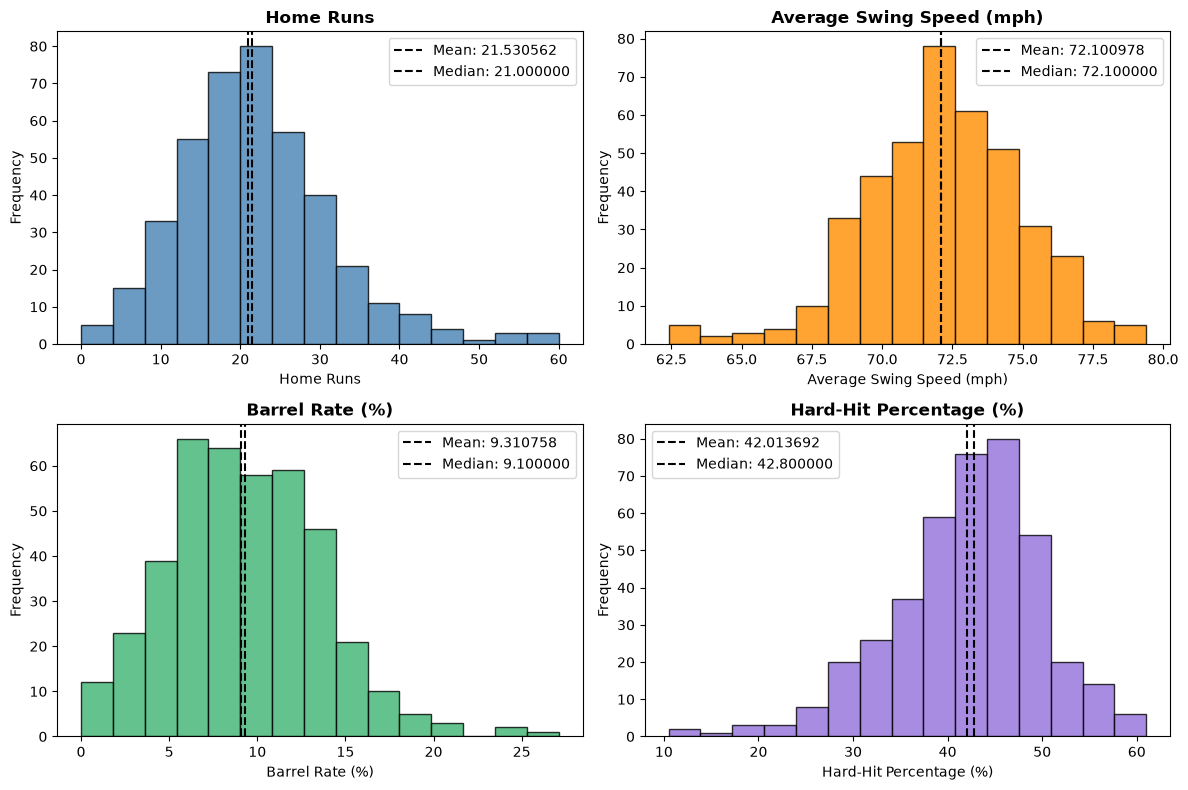

In [17]:
# Define clear titles for each batting statistic
titles = {
    "home_run": "Home Runs",
    "avg_swing_speed": "Average Swing Speed (mph)",
    "barrel_batted_rate": "Barrel Rate (%)",
    "hard_hit_percent": "Hard-Hit Percentage (%)",
}

# Create a 2x2 layout for the histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Create a histogram for each batting statistic
for column, colour, ax in zip(batting_columns, colours, axes.flat):

    # Display the distribution
    ax.hist(df[column], bins=15, color=colour,
            edgecolor="black", alpha=0.8)

    # Calculate the mean and median
    mean = df[column].mean()
    median = df[column].median()

    # Add the mean and median reference lines
    ax.axvline(mean, color="black", linestyle="--",
            label=f"Mean: {mean:2f}")
    ax.axvline(median, color="black", linestyle="--",
            label=f"Median: {median:2f}")

    # Add titles, axis labels and legend
    ax.set_title(titles[column], fontsize=12, fontweight="bold")
    ax.set_xlabel(titles[column])
    ax.set_ylabel("Frequency")
    ax.legend()

# Adjust spacing and display the histograms
plt.tight_layout()
plt.show()

## References 

McQuiad, D. (2026) <em> 'Data Preparation Module Notes'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3680 (Access: 15 November 2026).

Eccher, C. (2026) <em> 'Statistical Techniques for Data Analysis'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3681 (Accessed: 15 November 2026).

Iqbal, M. (2026) <em> 'Machine Learning'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3682 (Accessed: 15 November 2026).

Ahmed, T. (2026) <em> 'Strategic Thinking'. </em> Available at: https://moodle.cct.ie/course/view.php?id=3679 (Accessed: 15 November 2026).

Markdown Guide. (2026). <em> 'Basic Synthax'. </em> Available at: https://markdownguide.offshoot.io/basic-syntax/ (Accessed: 15 November 2026).

Major League Baseball (2026) <em> 'Baseball Savant: Custom Leaderboard - MLB Batting Statistics, 2024-2026'. </em> Available at: https://baseballsavant.mlb.com/leaderboard/custom?year=2026%2C2025%2C2024&type=batter&filter=&min=q&selections=player_age%2Cpa%2Chome_run%2Cavg_swing_speed%2Cfast_swing_rate%2Claunch_angle_avg%2Csweet_spot_percent%2Cbarrel_batted_rate%2Chard_hit_percent%2Cwhiff_percent%2Cswing_percent&chart=false&x=pa&y=pa&r=no&chartType=beeswarm&sort=player_name&sortDir=desc (Accessed: 15 November 2026).

pandas (2026) <em> 'pandas.DataFrame.duplicated'. </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html (Accessed: 15 November 2026).

pandas (2026) <em> 'pandas.DataFrame.hist'. </em> Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html (Accessed: 15 November 2026).

Matplotlib Development Team (2026) <em> 'matplotlib.pyplot.tight_layout'. </em> Available at: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.tight_layout.html (Accessed: 15 November 2026).